# Retenção com movimentação

Case técnico – Cientista de Dados · leads do funil de retenção, jun–dez/2025

**Objetivo:** identificar o perfil dos clientes retidos que alteram algum produto (BL, TV, fone ou móvel).

**Resultados em resumo**
- Quem paga acima do preço típico do produto equivalente (*sobrepreço*) movimenta ~40%; abaixo, ~21%.
- Movimentar é migrar para o catálogo atual: mais velocidade ou TV streaming por menos.
- Cliente convergente (móvel, mais produtos, fatura unificada, fibra) é o mais propenso.
- SOLAR retém +8,2 p.p. a mais que o Legado em clientes equivalentes.

## 1. Contexto

A retenção quer saber quem aceita trocar de produto para ficar, sem perder receita – por isso olho taxa e R$ juntos. Limpeza e variáveis ficam em `src/` (o dashboard usa as mesmas funções).

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ))

from src.preparacao import (carregar_base, preparar_base, classificar_tv, PRODUTOS, COL_ID,
                            VARS_NUMERICAS, VARS_CATEGORICAS)
from src.perfis import regras_folhas, texto_regra
from src import visual as vz

vz.aplicar_estilo()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

SEED = 42
DIR_FIG = RAIZ / "outputs" / "figuras"
DIR_APP = RAIZ / "outputs" / "app"
DIR_MOD = RAIZ / "outputs" / "modelos"
for d in (DIR_FIG, DIR_APP, DIR_MOD):
    d.mkdir(parents=True, exist_ok=True)

def salvar(fig, nome):
    fig.savefig(DIR_FIG / f"{nome}.png", bbox_inches="tight", dpi=150)

def br(n, casas=0):
    # formata número no padrão brasileiro
    return f"{n:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

## 2. Qualidade da base

In [2]:
bruta = carregar_base()
print(f"{br(bruta.shape[0])} linhas x {bruta.shape[1]} colunas")
print(f"{br(bruta['id_cliente'].nunique())} clientes distintos")
print(bruta["DATA_FUNIL_SOLAR"].dt.to_period("M").value_counts().sort_index().to_string())
print("Colunas:", ", ".join(bruta.columns))

303.654 linhas x 48 colunas
287.979 clientes distintos
DATA_FUNIL_SOLAR
2025-02        1
2025-05        1
2025-06    43218
2025-07    43244
2025-08    43418
2025-09    43470
2025-10    43509
2025-11    43337
2025-12    43456
Freq: M
Colunas: id_cliente, DATA_FUNIL_SOLAR, COD_IBGE, DSC_CIDADE, SGL_UF, flag_movel, DSC_CLI_MPLAY_M0, DSC_CLI_MPLAY_M30, NM_SUB_INDICADOR_NEGOCIO, NM_GRUPO_REGIONAL, FLAG_ORIGEM, ID_PRODUTO_BL_M0, DSC_PRODUTO_BL_M0, VALOR_BL_M0, ID_PRODUTO_BL_M30, DSC_PRODUTO_BL_M30, VALOR_BL_M30, ID_PRODUTO_TV_M0, DSC_PRODUTO_TV_M0, VALOR_TV_M0, ID_PRODUTO_TV_M30, DSC_PRODUTO_TV_M30, VALOR_TV_M30, ID_PRODUTO_FONE_M0, DSC_PRODUTO_FONE_M0, VALOR_FONE_M0, ID_PRODUTO_FONE_M30, DSC_PRODUTO_FONE_M30, VALOR_FONE_M30, COD_PLANO_MOVEL_M0, DSC_PLANO_MOVEL_M0, VALOR_MV_M0, COD_PLANO_MOVEL_M30, DSC_PLANO_MOVEL_M30, VALOR_MV_M30, FLAG_MOV_BL, FLAG_MOV_TV, FLAG_MOV_FONE, FLAG_MOV_MV, FLAG_CANC_BL, FLAG_CANC_TV, FLAG_CANC_FONE, FLAG_CANC_MV, MEIO_FISICO_BROWNFIELD, FLG_BROWNFIELD, TP_REDE_H

Formato largo: código, descrição e valor de cada produto em **M0** (entrada) e **M30** (saída). ~43 mil leads/mês; removo 2 leads fora do período.

In [3]:
perfil = pd.DataFrame({
    "tipo": bruta.dtypes.astype(str),
    "nulos": bruta.isna().sum(),
    "% nulos": bruta.isna().mean().round(3),
    "distintos": bruta.nunique(),
})
perfil[perfil["nulos"] > 0].sort_values("% nulos", ascending=False)

,tipo,nulos,% nulos,distintos
DSC_PLANO_MOVEL_M0,object,291022,0.958,261
DSC_PLANO_MOVEL_M30,object,291022,0.958,190
DSC_CLI_MPLAY_M0,object,283458,0.933,2
DSC_CLI_MPLAY_M30,object,282233,0.929,2
MEIO_FISICO_BROWNFIELD,object,241974,0.797,3
DSC_PRODUTO_FONE_M30,object,230981,0.761,364
DSC_PRODUTO_FONE_M0,object,204296,0.673,394
DSC_PRODUTO_TV_M30,object,178403,0.588,1727
DSC_PRODUTO_TV_M0,object,148335,0.489,1937
DSC_PRODUTO_BL_M30,object,70209,0.231,1417


Nulos não são dado faltante: descrição vazia = não tem o produto; MPLAY vazio = não elegível.

Clientes repetidos:

In [4]:
rep = bruta[bruta["id_cliente"].duplicated(keep=False)].sort_values(["id_cliente", "DATA_FUNIL_SOLAR"])
intervalo = rep.groupby("id_cliente")["DATA_FUNIL_SOLAR"].agg(lambda s: (s.max() - s.min()).days)

print(f"Linhas idênticas: {bruta.duplicated().sum()}")
print(f"Clientes com mais de um lead: {br(rep['id_cliente'].nunique())} ({br(len(rep))} linhas)")
print(f"Mesmo cliente e mesmo horário de entrada: {rep.duplicated(['id_cliente', 'DATA_FUNIL_SOLAR']).sum()}")
print("\nDias entre o primeiro e o último lead do cliente:")
intervalo.describe(percentiles=[.25, .5, .75]).round(0)

Linhas idênticas: 0
Clientes com mais de um lead: 14.069 (29.744 linhas)
Mesmo cliente e mesmo horário de entrada: 165

Dias entre o primeiro e o último lead do cliente:


count   14,069.000
mean        52.000
std         49.000
min          0.000
25%         10.000
50%         36.000
75%         82.000
max        212.000
Name: DATA_FUNIL_SOLAR, dtype: float64

São clientes que voltaram ao funil (mediana de 36 dias), não duplicatas. Mantenho todos e crio `n_leads_anteriores`.

Conferindo o significado dos flags contra os códigos de produto:

In [5]:
def situacao_produto(df, p):
    a, b = COL_ID[p].format(m="M0"), COL_ID[p].format(m="M30")
    tinha, tem = df[a] > 0, df[b] > 0
    return np.select(
        [~tinha & ~tem, tinha & ~tem, ~tinha & tem, tinha & tem & (df[a] != df[b])],
        ["não tinha", "perdeu o produto", "ganhou o produto", "trocou de produto"],
        "mesmo produto",
    )

tabelas = []
for p in PRODUTOS:
    t = pd.crosstab(situacao_produto(bruta, p),
                    [bruta[f"FLAG_MOV_{p}"].rename("mov"), bruta[f"FLAG_CANC_{p}"].rename("canc")])
    t.index.name = p
    tabelas.append(t)
    display(t)

mov                     0             1
canc                    0      1      0
BL                                     
mesmo produto      157485      0      0
não tinha           12751      0      0
perdeu o produto        0  56351      0
trocou de produto       0      0  77067

mov                     0             1
canc                    0      1      0
TV                                     
mesmo produto       99912      0      0
não tinha          148335      0      0
perdeu o produto        0  30068      0
trocou de produto       0      0  25339

mov                     0             1
canc                    0      1      0
FONE                                   
mesmo produto       62904      0      0
não tinha          203726      0      0
perdeu o produto        0  26735      0
trocou de produto       0      0  10289

mov,0,1
canc,0,0
MV,,
mesmo produto,7774,0
não tinha,291024,0
trocou de produto,0,4856


`FLAG_MOV` = trocou de produto; `FLAG_CANC` = perdeu o produto. Ninguém ganhou produto novo.

Status do lead x receita em M30:

In [6]:
df = preparar_base()

df["receita_zerada_m30"] = (df["receita_m0"] > 0) & (df["receita_m30"] <= 0)
inconsist = pd.DataFrame({
    "leads": df.groupby("status").size(),
    "% com toda a receita zerada em M30": df.groupby("status")["receita_zerada_m30"].mean(),
    "% sem nenhum cancelamento": df.groupby("status")["cancelou_algum"].apply(lambda s: (s == 0).mean()),
})
inconsist

,leads,% com toda a receita zerada em M30,% sem nenhum cancelamento
status,,,
LEAD EM ABERTO,6252,0.343,0.489
NAO RETIDO,48091,0.648,0.254
RETIDO,249309,0.084,0.818


**8% dos RETIDOS zeram a receita em M30.** Mantenho o status oficial no alvo, mas acompanho o impacto em receita. Fone tem valor ~0 (posse medida pelo código).

## 3. Variáveis

Só entra no modelo o que se sabe em M0: tudo de M30 é resultado da oferta e seria vazamento. A principal variável criada é o **sobrepreço**: valor pago vs. mediana de produto equivalente (BL: velocidade + praça; TV: nível do pacote).

## 4. Análise descritiva

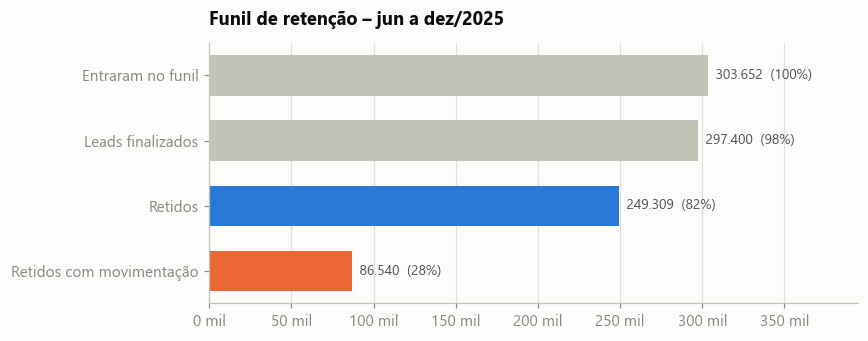

Taxa de retenção (sobre leads finalizados): 83.8%
Taxa de movimentação entre retidos: 34.7%


,leads,%
status,,
RETIDO,249309,0.821
NAO RETIDO,48091,0.158
LEAD EM ABERTO,6252,0.021


In [7]:
funil = df["status"].value_counts().rename("leads").to_frame()
funil["%"] = funil["leads"] / funil["leads"].sum()

fechados = df[df["status"] != "LEAD EM ABERTO"]
retidos = df[df["retido"] == 1].copy()
taxa_ret = fechados["retido"].mean()
taxa_mov = retidos["movimentou"].mean()

fig, ax = plt.subplots(figsize=(8, 3.2))
etapas = ["Entraram no funil", "Leads finalizados", "Retidos", "Retidos com movimentação"]
valores = [len(df), len(fechados), len(retidos), retidos["alvo_retido_mov"].sum()]
bars = ax.barh(etapas, valores, color=[vz.CINZA_CLARO, vz.CINZA_CLARO, vz.AZUL, vz.LARANJA], height=0.62)
for b, v in zip(bars, valores):
    ax.text(v, b.get_y() + b.get_height() / 2, f"  {br(v)}  ({v / len(df):.0%})", va="center", fontsize=9, color=vz.TINTA_2)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(vz.fmt_milhar)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlim(0, len(df) * 1.3)
ax.set_title("Funil de retenção – jun a dez/2025")
plt.tight_layout(); salvar(fig, "01_funil"); plt.show()

print(f"Taxa de retenção (sobre leads finalizados): {taxa_ret:.1%}")
print(f"Taxa de movimentação entre retidos: {taxa_mov:.1%}")
funil

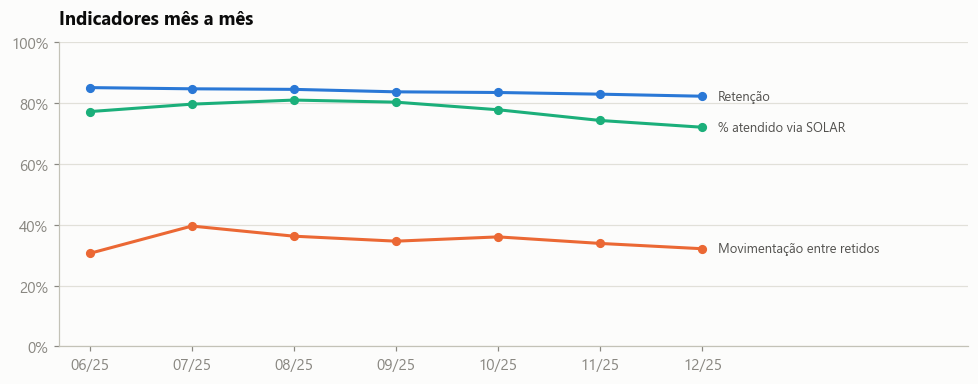

,leads,retencao,mov_entre_retidos,pct_solar
mes,,,,
2025-06,43218,0.851,0.306,0.772
2025-07,43244,0.847,0.396,0.797
2025-08,43418,0.845,0.362,0.810
2025-09,43470,0.837,0.346,0.803
2025-10,43509,0.835,0.360,0.778
2025-11,43337,0.829,0.338,0.743
2025-12,43456,0.823,0.321,0.721


In [8]:
mensal = (df.groupby("mes")
            .agg(leads=("id_lead", "size"),
                 retencao=("retido", lambda s: s[df.loc[s.index, "status"] != "LEAD EM ABERTO"].mean()),
                 mov_entre_retidos=("alvo_retido_mov", lambda s: s[df.loc[s.index, "retido"] == 1].mean()),
                 pct_solar=("FLAG_ORIGEM", lambda s: (s == "SOLAR").mean())))

fig, ax = plt.subplots(figsize=(9, 3.6))
x = range(len(mensal))
for col, cor, rot in [("retencao", vz.AZUL, "Retenção"),
                      ("mov_entre_retidos", vz.LARANJA, "Movimentação entre retidos"),
                      ("pct_solar", vz.VERDE_AGUA, "% atendido via SOLAR")]:
    ax.plot(x, mensal[col], marker="o", markersize=5, color=cor, label=rot)
    ax.text(len(mensal) - 0.85, mensal[col].iloc[-1], rot, color=vz.TINTA_2, fontsize=8.5, va="center")
ax.set_xticks(list(x), [m[-2:] + "/25" for m in mensal.index])
ax.yaxis.set_major_formatter(vz.fmt_pct)
ax.set_ylim(0, 1); ax.set_xlim(-0.3, len(mensal) + 1.6)
ax.set_title("Indicadores mês a mês")
plt.tight_layout(); salvar(fig, "02_mensal"); plt.show()
mensal

Movimentação com pico em julho e queda até dezembro – por isso valido o modelo no tempo.

### Taxa de movimentação por perfil (linha = média)

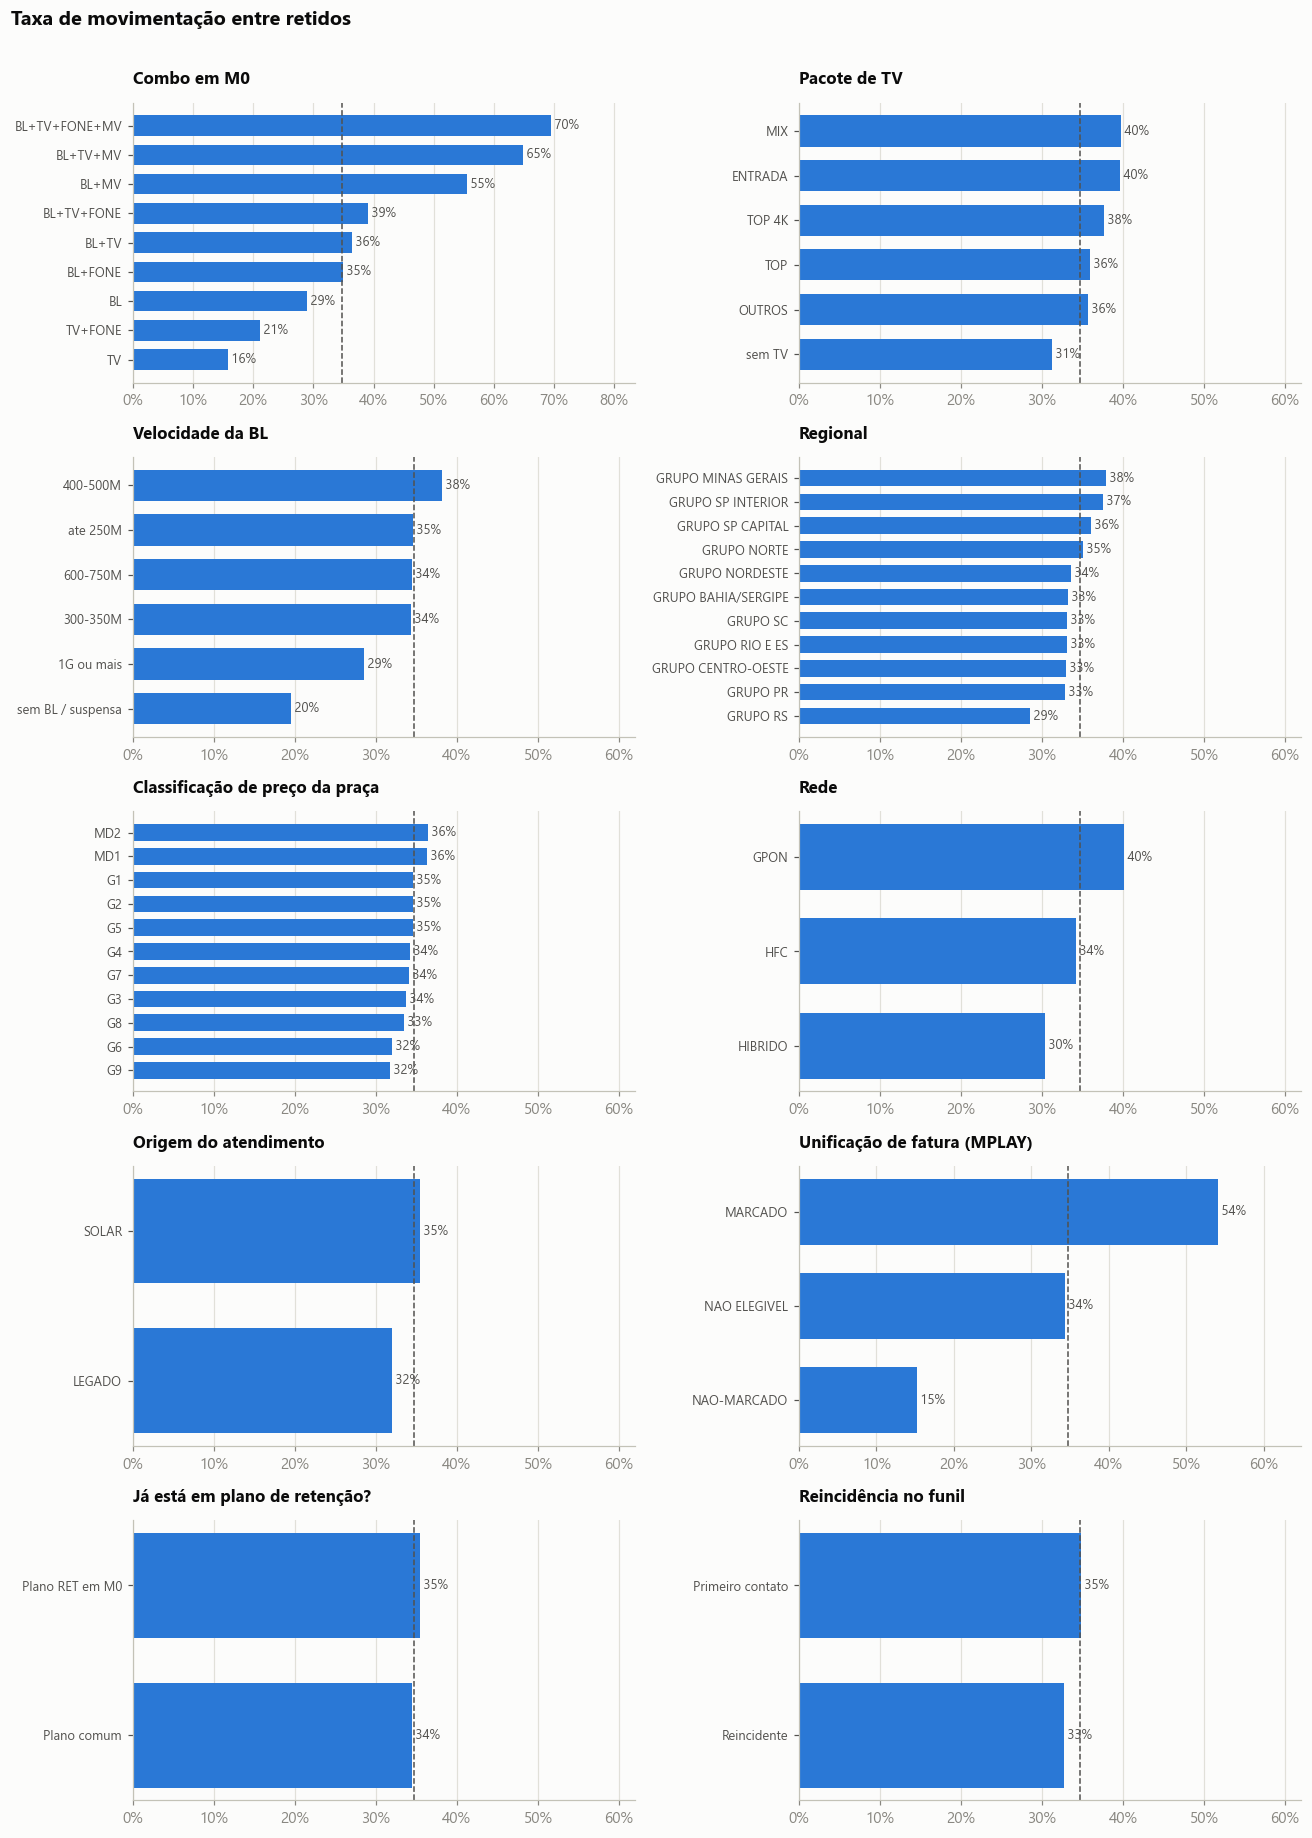

In [9]:
retidos["reincidente"] = np.where(retidos["n_leads_anteriores"] > 0, "Reincidente", "Primeiro contato")
retidos["tem_plano_ret"] = np.where(retidos["plano_de_retencao_m0"] == 1, "Plano RET em M0", "Plano comum")
retidos["unif_fatura"] = retidos["DSC_CLI_MPLAY_M0"]

dimensoes = {
    "combo_m0": "Combo em M0",
    "tier_tv": "Pacote de TV",
    "faixa_velocidade_bl": "Velocidade da BL",
    "NM_GRUPO_REGIONAL": "Regional",
    "CLASSIFICACAO": "Classificação de preço da praça",
    "TP_REDE_HP": "Rede",
    "FLAG_ORIGEM": "Origem do atendimento",
    "unif_fatura": "Unificação de fatura (MPLAY)",
    "tem_plano_ret": "Já está em plano de retenção?",
    "reincidente": "Reincidência no funil",
}

def taxa_por(dfx, col, alvo="alvo_retido_mov", minimo=1000):
    t = dfx.groupby(col, observed=True)[alvo].agg(["mean", "size"])
    return t[t["size"] >= minimo].sort_values("mean", ascending=False)

fig, axes = plt.subplots(5, 2, figsize=(12, 17))
for ax, (col, titulo) in zip(axes.flat, dimensoes.items()):
    t = taxa_por(retidos, col)
    vz.barras_h(ax, t.index.astype(str), t["mean"], cor=vz.AZUL)
    ax.axvline(taxa_mov, color=vz.TINTA_2, ls="--", lw=1)
    ax.set_xlim(0, max(0.62, t["mean"].max() * 1.2))
    ax.xaxis.set_major_formatter(vz.fmt_pct)
    ax.set_title(titulo, fontsize=11)
    ax.tick_params(axis="y", labelsize=8.5, colors=vz.TINTA_2)
fig.suptitle("Taxa de movimentação entre retidos", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.975)); salvar(fig, "03_taxa_por_perfil"); plt.show()

- Convergência é o maior diferenciador: combos com móvel 55–70%; só BL 29%; só TV 16%.
- Fatura unificada 54% x elegível sem unificar 15%; GPON 40% x HFC 34%.
- Esperava que plano RET reduzisse a movimentação – não reduz.

### Sobrepreço

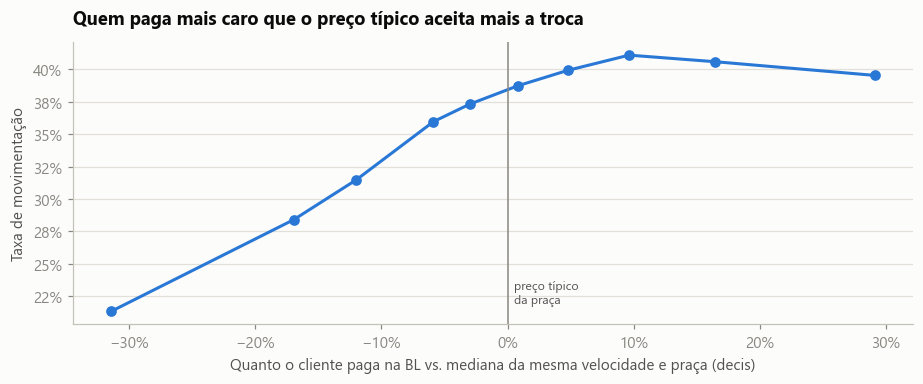

,taxa,sobrepreco_medio,leads
decil_sobrepreco_bl,,,
"(-0.947, -0.222]",0.213,-0.314,23356
"(-0.222, -0.167]",0.284,-0.169,24199
"(-0.167, -0.09]",0.315,-0.120,22891
"(-0.09, -0.0449]",0.360,-0.059,23700
"(-0.0449, -0.00477]",0.373,-0.030,22936
"(-0.00477, 0.027]",0.387,0.008,23818
"(0.027, 0.0772]",0.399,0.048,22350
"(0.0772, 0.125]",0.411,0.096,23365
"(0.125, 0.205]",0.406,0.165,23581


In [10]:
retidos["decil_sobrepreco_bl"] = pd.qcut(retidos["sobrepreco_bl"], 10, duplicates="drop")
curva = retidos.groupby("decil_sobrepreco_bl", observed=True).agg(
    taxa=("alvo_retido_mov", "mean"), sobrepreco_medio=("sobrepreco_bl", "median"), leads=("id_lead", "size"))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(curva["sobrepreco_medio"], curva["taxa"], marker="o", color=vz.AZUL)
ax.axvline(0, color=vz.CINZA, lw=1)
ax.text(0.005, 0.22, "preço típico\nda praça", fontsize=8, color=vz.TINTA_2)
ax.xaxis.set_major_formatter(vz.fmt_pct); ax.yaxis.set_major_formatter(vz.fmt_pct)
ax.set_xlabel("Quanto o cliente paga na BL vs. mediana da mesma velocidade e praça (decis)")
ax.set_ylabel("Taxa de movimentação")
ax.set_title("Quem paga mais caro que o preço típico aceita mais a troca")
plt.tight_layout(); salvar(fig, "04_sobrepreco"); plt.show()
curva

Abaixo do preço típico ~21%; no preço ou acima, ~40%.

### Para onde vai a receita do funil

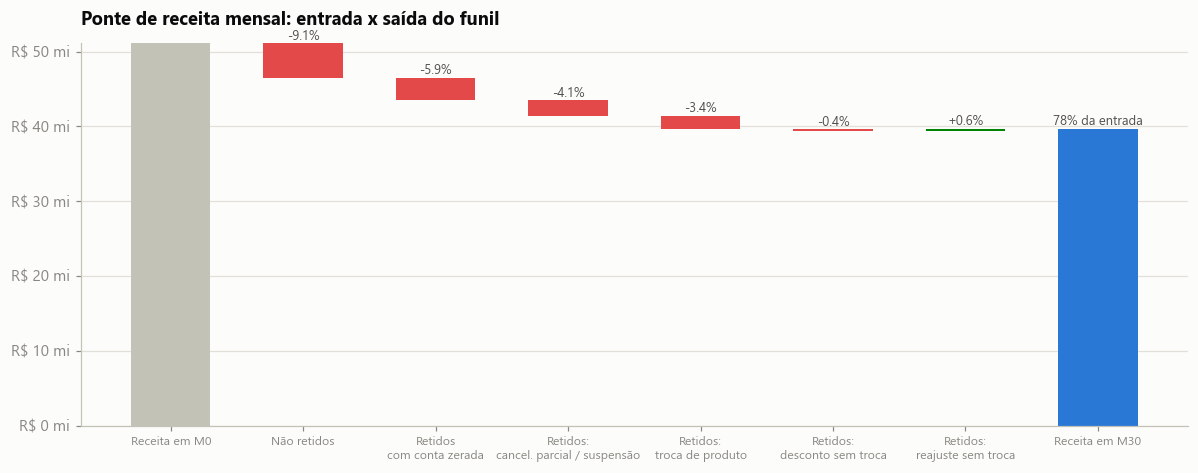

Receita mensal na entrada: R$ 51.110.168 | na saída: R$ 39.700.441 (77.7%)


,R$ mensais,% da receita de entrada
componente,,
Não retidos,"-4,647,993.200",-0.091
Retidos com conta zerada,"-2,997,018.800",-0.059
Retidos: cancel. parcial / suspensão,"-2,113,695.140",-0.041
Retidos: troca de produto,"-1,758,518.880",-0.034
Retidos: desconto sem troca,"-224,048.170",-0.004
Retidos: reajuste sem troca,"331,481.400",0.006


In [11]:
f = fechados.copy()
f["componente"] = np.select(
    [f["status"] == "NAO RETIDO",
     f["receita_zerada_m30"],
     f["tipo_desfecho"].isin(["Cancelamento parcial", "Troca + cancelamento parcial", "Suspensao temporaria"]),
     f["tipo_desfecho"].str.startswith("Troca"),
     f["tipo_desfecho"] == "Desconto sem troca",
     f["tipo_desfecho"] == "Reajuste sem troca"],
    ["Não retidos", "Retidos com conta zerada", "Retidos: cancel. parcial / suspensão", "Retidos: troca de produto",
     "Retidos: desconto sem troca", "Retidos: reajuste sem troca"],
    "Retidos sem alteração")

entrada = f["receita_m0"].sum()
fluxo = f.groupby("componente")["delta_receita"].sum()
ordem = ["Não retidos", "Retidos com conta zerada", "Retidos: cancel. parcial / suspensão", "Retidos: troca de produto",
         "Retidos: desconto sem troca", "Retidos: reajuste sem troca"]
fluxo = fluxo.reindex(ordem)
saida = f["receita_m30"].sum()

fig, ax = plt.subplots(figsize=(11, 4.4))
rotulos = ["Receita em M0"] + [o.replace(": ", ":\n").replace(" com ", "\ncom ") for o in ordem] + ["Receita em M30"]
base = entrada
ax.bar(0, entrada, color=vz.CINZA_CLARO, width=0.6)
for i, (nome, v) in enumerate(fluxo.items(), start=1):
    cor = vz.CORES[7] if v < 0 else vz.CORES[5]
    ax.bar(i, v, bottom=base, color=cor, width=0.6)
    ax.text(i, base + max(v, 0) + entrada * 0.01, f"{'+' if v > 0 else ''}{v / entrada:.1%}", ha="center", fontsize=8.5, color=vz.TINTA_2)
    base += v
ax.bar(len(rotulos) - 1, saida, color=vz.AZUL, width=0.6)
ax.text(len(rotulos) - 1, saida + entrada * 0.01, f"{saida / entrada:.0%} da entrada", ha="center", fontsize=8.5, color=vz.TINTA_2)
ax.set_xticks(range(len(rotulos)), rotulos, fontsize=8)
ax.yaxis.set_major_formatter(vz.FuncFormatter(lambda v, _: f"R$ {v / 1e6:.0f} mi"))
ax.set_title("Ponte de receita mensal: entrada x saída do funil")
plt.tight_layout(); salvar(fig, "05_ponte_receita"); plt.show()

ponte = pd.DataFrame({"R$ mensais": fluxo, "% da receita de entrada": fluxo / entrada})
print(f"Receita mensal na entrada: R$ {br(entrada)} | na saída: R$ {br(saida)} ({saida / entrada:.1%})")
ponte

Os retidos levam mais receita (13%) que os não retidos (9%) – principalmente retidos que zeram a conta.

## 5. Tipos de movimentação

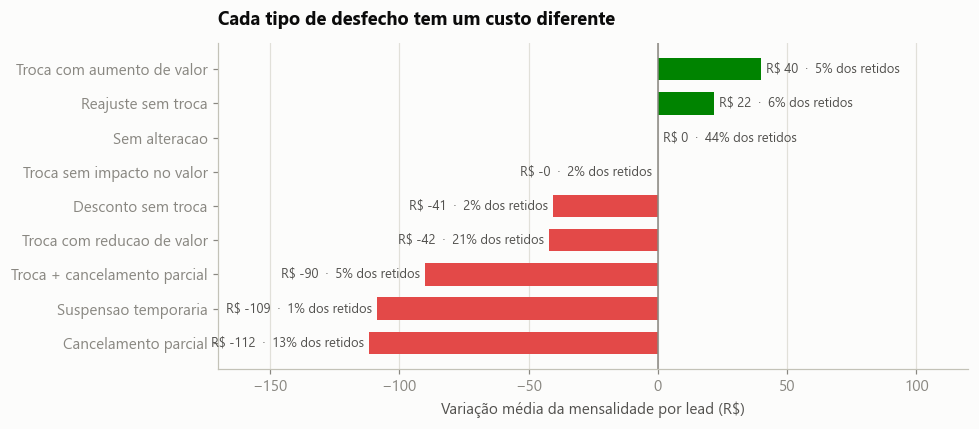

,leads,% dos retidos,receita_m0_media,delta_medio,receita_preservada,delta_mensal_total
tipo_desfecho,,,,,,
Sem alteracao,109648,0.440,168.338,0.001,1.000,9.310
Troca com reducao de valor,53059,0.213,196.834,-42.050,0.809,"-318,731.039"
Cancelamento parcial,32318,0.130,167.231,-111.527,0.000,"-514,902.129"
Reajuste sem troca,15261,0.061,184.974,21.721,1.085,"47,354.486"
Troca + cancelamento parcial,13060,0.052,211.675,-90.085,0.539,"-168,072.797"
Troca com aumento de valor,11672,0.047,167.740,40.019,1.131,"66,728.416"
Troca sem impacto no valor,5771,0.023,129.422,-0.002,1.000,-1.749
Desconto sem troca,5542,0.022,255.351,-40.593,0.880,"-32,138.060"
Suspensao temporaria,2978,0.012,118.326,-108.616,0.000,"-46,208.499"


In [12]:
tipo = (retidos.groupby("tipo_desfecho")
          .agg(leads=("id_lead", "size"),
               receita_m0_media=("receita_m0", "mean"),
               delta_medio=("delta_receita", "mean"),
               receita_preservada=("receita_preservada_pct", "median"),
               delta_mensal_total=("delta_receita", "sum"))
          .sort_values("leads", ascending=False))
tipo["% dos retidos"] = tipo["leads"] / tipo["leads"].sum()
tipo["delta_mensal_total"] = tipo["delta_mensal_total"] / retidos["mes"].nunique()
tipo = tipo[["leads", "% dos retidos", "receita_m0_media", "delta_medio", "receita_preservada", "delta_mensal_total"]]

fig, ax = plt.subplots(figsize=(9, 4))
t = tipo.sort_values("delta_medio")
cores = [vz.CORES[7] if v < -1 else (vz.CORES[5] if v > 1 else vz.CINZA_CLARO) for v in t["delta_medio"]]
bars = ax.barh(t.index, t["delta_medio"], color=cores, height=0.65)
for b, (v, n) in zip(bars, zip(t["delta_medio"], t["% dos retidos"])):
    ax.text(v + (2 if v >= 0 else -2), b.get_y() + b.get_height() / 2,
            f"R$ {v:,.0f}  ·  {n:.0%} dos retidos", va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=vz.TINTA_2)
ax.axvline(0, color=vz.CINZA, lw=1)
ax.set_xlim(-170, 120)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Variação média da mensalidade por lead (R$)")
ax.set_title("Cada tipo de desfecho tem um custo diferente")
plt.tight_layout(); salvar(fig, "06_tipologia"); plt.show()
tipo

Troca com redução é o tipo mais comum; 5% dos retidos saem pagando mais.

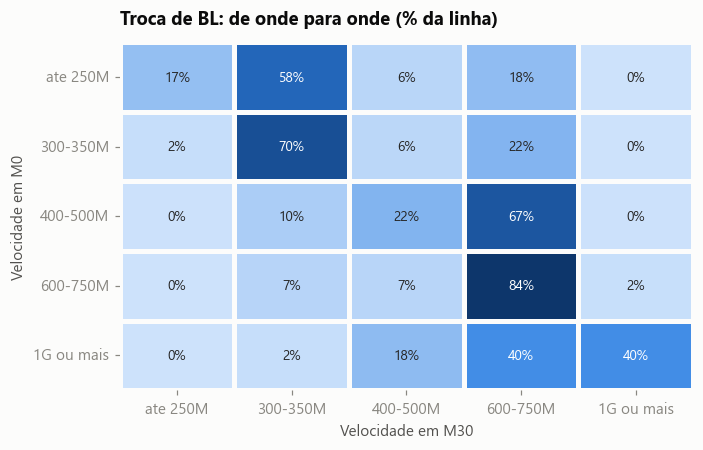

,leads,delta_bl_medio,%
direcao_velocidade_bl,,,
downgrade,7442,-34.632,0.100
indefinido,3699,-66.200,0.050
mesma velocidade,32482,-23.525,0.437
upgrade,30632,-12.172,0.413


In [13]:
troca_bl = retidos[retidos["FLAG_MOV_BL"] == 1]
direcao = (troca_bl.groupby("direcao_velocidade_bl")
                   .agg(leads=("id_lead", "size"), delta_bl_medio=("delta_bl", "mean")))
direcao["%"] = direcao["leads"] / direcao["leads"].sum()

ordem_vel = ["ate 250M", "300-350M", "400-500M", "600-750M", "1G ou mais"]
faixa_m30 = pd.cut(troca_bl["velocidade_bl_m30"], [0, 299, 399, 549, 799, np.inf], labels=ordem_vel)
matriz = pd.crosstab(troca_bl["faixa_velocidade_bl"], faixa_m30, normalize="index").reindex(index=ordem_vel, columns=ordem_vel)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.heatmap(matriz, annot=True, fmt=".0%", cmap=sns.blend_palette(vz.SEQUENCIAL, as_cmap=True),
            cbar=False, linewidths=2, linecolor=vz.FUNDO, ax=ax, annot_kws={"fontsize": 9})
ax.set_xlabel("Velocidade em M30"); ax.set_ylabel("Velocidade em M0")
ax.set_title("Troca de BL: de onde para onde (% da linha)")
plt.tight_layout(); salvar(fig, "07_matriz_velocidade"); plt.show()
direcao

Só 10% das trocas de BL são downgrade – e mesmo no upgrade a conta cai.

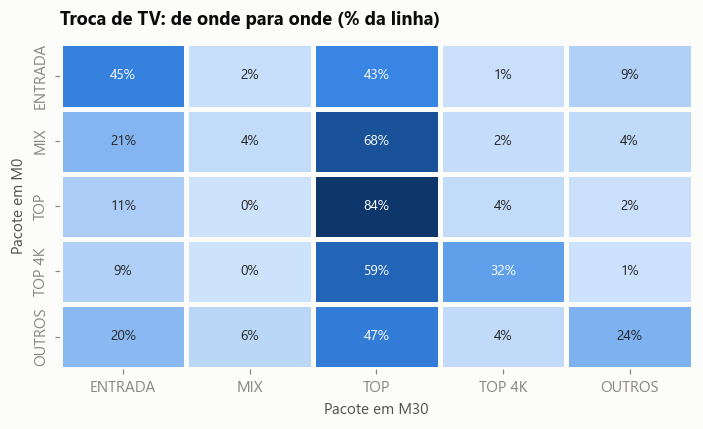

Variação média do valor da TV entre quem trocou: R$ -30.76
% das trocas de TV que foram para pacote de streaming: 87%


In [14]:
troca_tv = retidos[retidos["FLAG_MOV_TV"] == 1]
tier_m30 = classificar_tv(troca_tv["DSC_PRODUTO_TV_M30"])
ordem_tv = ["ENTRADA", "MIX", "TOP", "TOP 4K", "OUTROS"]
matriz_tv = pd.crosstab(troca_tv["tier_tv"], tier_m30, normalize="index").reindex(index=ordem_tv, columns=ordem_tv).fillna(0)

fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(matriz_tv, annot=True, fmt=".0%", cmap=sns.blend_palette(vz.SEQUENCIAL, as_cmap=True),
            cbar=False, linewidths=2, linecolor=vz.FUNDO, ax=ax, annot_kws={"fontsize": 9})
ax.set_xlabel("Pacote em M30"); ax.set_ylabel("Pacote em M0")
ax.set_title("Troca de TV: de onde para onde (% da linha)")
plt.tight_layout(); salvar(fig, "08_matriz_tv"); plt.show()

print("Variação média do valor da TV entre quem trocou:", f"R$ {troca_tv['delta_tv'].mean():.2f}")
print("% das trocas de TV que foram para pacote de streaming:",
      f"{troca_tv['DSC_PRODUTO_TV_M30'].str.contains('STREAMING|CTV\\+|TVMAIS').mean():.0%}")

87% das trocas de TV vão para streaming. Movimentar = migrar para o catálogo atual, mais por menos.

## 6. Modelagem

- População: RETIDOS; alvo = 1 se trocou ao menos um produto (`FLAG_MOV`).
- Treino jun–out, teste nov–dez: simula o uso real (treinar no passado, aplicar no futuro).
- Logística para interpretar efeitos; LightGBM para capturar não linearidades.
- Métricas: AUC/PR-AUC e taxa por decil, que é o que importa para priorizar clientes.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
import lightgbm as lgb

VARS = VARS_NUMERICAS + VARS_CATEGORICAS
y = retidos["alvo_retido_mov"]
treino = retidos["mes"] <= "2025-10"
teste = ~treino
valid = retidos["mes"] == "2025-10"

print(f"Treino: {br(treino.sum())} leads  | taxa = {y[treino].mean():.1%}")
print(f"Teste : {br(teste.sum())} leads  | taxa = {y[teste].mean():.1%}")

Treino: 179.862 leads  | taxa = 35.4%
Teste : 69.447 leads  | taxa = 33.0%


### Regressão logística
Categoria mais comum como referência; tirei variáveis redundantes (combo, faixa de velocidade, UF, tipo de móvel).

In [16]:
cat_log = [c for c in VARS_CATEGORICAS if c not in ("combo_m0", "faixa_velocidade_bl", "SGL_UF", "tipo_movel")]
num_log = [c for c in VARS_NUMERICAS if c != "dias_desde_lead_anterior"]
referencias = [retidos.loc[treino, c].mode()[0] for c in cat_log]

prep_log = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0)),
                      ("pad", StandardScaler())]), num_log),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=500, drop=referencias,
                          sparse_output=False), cat_log),
])
logit = Pipeline([("prep", prep_log), ("modelo", LogisticRegression(max_iter=3000, C=0.5))])
VARS_LOG = num_log + cat_log
logit.fit(retidos.loc[treino, VARS_LOG], y[treino])
p_log = logit.predict_proba(retidos.loc[teste, VARS_LOG])[:, 1]
print("Referências:", dict(zip(cat_log, referencias)))
print(f"Logística – AUC teste: {roc_auc_score(y[teste], p_log):.3f} | PR-AUC: {average_precision_score(y[teste], p_log):.3f}")

Referências: {'tier_tv': 'sem TV', 'DSC_CLI_MPLAY_M0': 'NAO ELEGIVEL', 'NM_GRUPO_REGIONAL': 'GRUPO SP CAPITAL', 'CLASSIFICACAO': 'G1', 'TP_REDE_HP': 'HFC', 'FLAG_ORIGEM': 'SOLAR'}
Logística – AUC teste: 0.652 | PR-AUC: 0.482


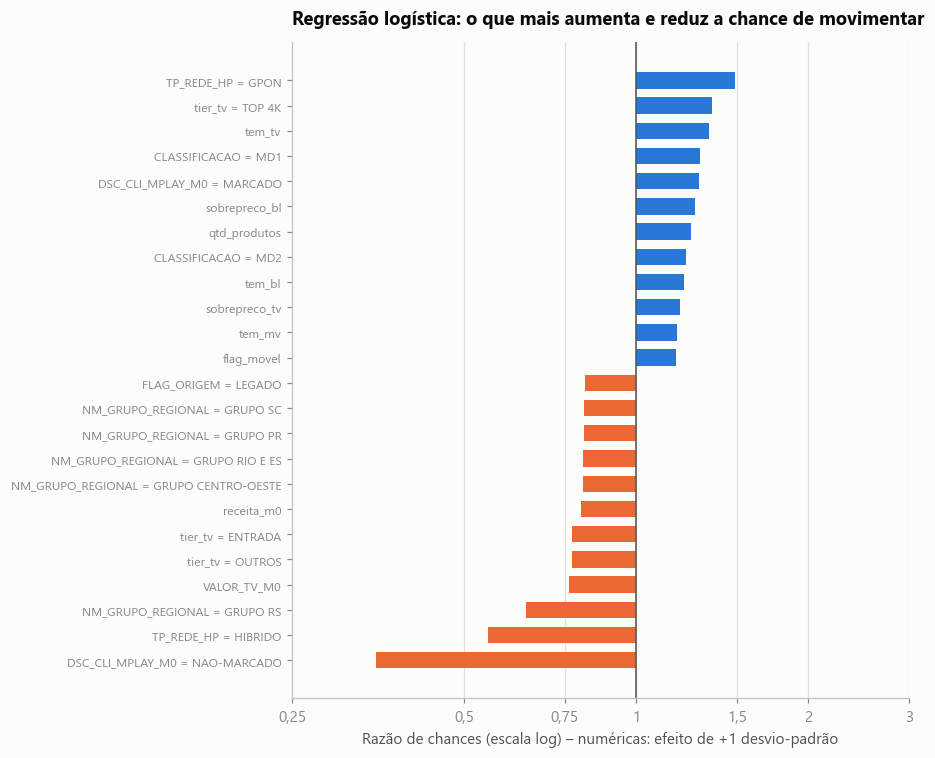

In [17]:
nomes = logit.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logit.named_steps["modelo"].coef_[0], index=nomes)
coefs = coefs[~coefs.index.str.contains("infrequent")]

def nome_legivel(n):
    n = n.replace("num__", "").replace("cat__", "")
    for c in cat_log:
        if n.startswith(c + "_"):
            return f"{c} = {n[len(c) + 1:]}"
    return n

coefs.index = [nome_legivel(n) for n in coefs.index]
odds = np.exp(coefs).rename("razao_de_chances").to_frame()
odds["efeito"] = np.where(odds["razao_de_chances"] > 1, "aumenta", "reduz")

destaque = pd.concat([odds.nlargest(12, "razao_de_chances"), odds.nsmallest(12, "razao_de_chances")])
fig, ax = plt.subplots(figsize=(8.5, 7))
d = destaque.sort_values("razao_de_chances")
ax.barh(d.index, d["razao_de_chances"] - 1, left=1,
        color=[vz.AZUL if v > 1 else vz.LARANJA for v in d["razao_de_chances"]], height=0.65)
ax.axvline(1, color=vz.TINTA_2, lw=1)
ax.set_xscale("log")
marcas = [0.25, 0.5, 0.75, 1, 1.5, 2, 3]
ax.set_xticks(marcas, [str(m).replace(".", ",") for m in marcas])
ax.minorticks_off()
ax.set_xlabel("Razão de chances (escala log) – numéricas: efeito de +1 desvio-padrão")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.tick_params(axis="y", labelsize=8)
ax.set_title("Regressão logística: o que mais aumenta e reduz a chance de movimentar")
plt.tight_layout(); salvar(fig, "09_odds_logistica"); plt.show()

Com o resto fixo, ticket alto reduz a chance: o que pesa é pagar caro **para aquele produto** (sobrepreço).

### LightGBM

In [18]:
X = retidos[VARS].copy()
for c in VARS_CATEGORICAS:
    X[c] = X[c].astype("category")

params = dict(learning_rate=0.03, num_leaves=48, min_child_samples=200, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.7, reg_lambda=5, cat_smooth=50, random_state=SEED, verbose=-1)

ajuste = treino & ~valid
m = lgb.LGBMClassifier(n_estimators=3000, **params)
m.fit(X[ajuste], y[ajuste], eval_set=[(X[valid], y[valid])], eval_metric="auc",
      callbacks=[lgb.early_stopping(100, verbose=False)])
n_arvores = m.best_iteration_
print("Número de árvores escolhido:", n_arvores)

gbm = lgb.LGBMClassifier(n_estimators=n_arvores, **params)
gbm.fit(X[treino], y[treino])
p_gbm = gbm.predict_proba(X[teste])[:, 1]
print(f"LightGBM – AUC teste: {roc_auc_score(y[teste], p_gbm):.3f} | PR-AUC: {average_precision_score(y[teste], p_gbm):.3f}")

Número de árvores escolhido: 352


LightGBM – AUC teste: 0.687 | PR-AUC: 0.528


### Comparação

In [19]:
def tabela_decis(y_true, score, n=10):
    t = pd.DataFrame({"y": np.asarray(y_true), "s": score})
    t["decil"] = pd.qcut(t["s"].rank(method="first", ascending=False), n, labels=range(1, n + 1))
    g = t.groupby("decil", observed=True).agg(leads=("y", "size"), taxa=("y", "mean"), escore_medio=("s", "mean"))
    g["lift"] = g["taxa"] / t["y"].mean()
    g["% dos movimentadores acumulado"] = (g["taxa"] * g["leads"]).cumsum() / t["y"].sum()
    return g

def metricas(nome, y_true, score):
    dec = tabela_decis(y_true, score)
    return pd.Series({
        "AUC": roc_auc_score(y_true, score),
        "PR-AUC": average_precision_score(y_true, score),
        "Brier": brier_score_loss(y_true, score),
        "Lift decil 1": dec["lift"].iloc[0],
        "% capturado no top 30%": dec["% dos movimentadores acumulado"].iloc[2],
    }, name=nome)

base_taxa = np.full(teste.sum(), y[treino].mean())
comparacao = pd.concat([metricas("Taxa média (sem modelo)", y[teste], base_taxa + np.random.default_rng(SEED).normal(0, 1e-6, teste.sum())),
                        metricas("Regressão logística", y[teste], p_log),
                        metricas("LightGBM", y[teste], p_gbm)], axis=1).T
comparacao

,AUC,PR-AUC,Brier,Lift decil 1,% capturado no top 30%
Taxa média (sem modelo),0.499,0.330,0.222,1.001,0.301
Regressão logística,0.652,0.482,0.206,1.779,0.432
LightGBM,0.687,0.528,0.198,1.931,0.462


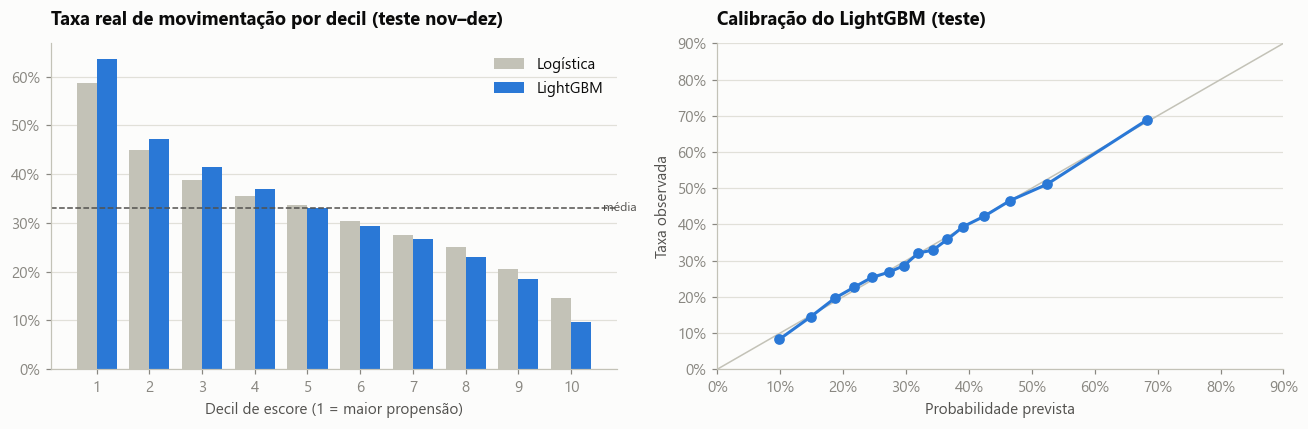

,leads,taxa,escore_medio,lift,% dos movimentadores acumulado
decil,,,,,
1,6945,0.637,0.636,1.931,0.193
2,6945,0.473,0.479,1.435,0.337
3,6944,0.414,0.415,1.256,0.462
4,6945,0.369,0.372,1.118,0.574
5,6945,0.330,0.337,1.000,0.674
6,6944,0.294,0.303,0.892,0.763
7,6945,0.268,0.266,0.813,0.845
8,6944,0.230,0.224,0.699,0.914
9,6945,0.185,0.178,0.560,0.970


In [20]:
dec_log, dec_gbm = tabela_decis(y[teste], p_log), tabela_decis(y[teste], p_gbm)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
w = 0.38
ax.bar(dec_log.index.astype(int) - w / 2, dec_log["taxa"], width=w, color=vz.CINZA_CLARO, label="Logística")
ax.bar(dec_gbm.index.astype(int) + w / 2, dec_gbm["taxa"], width=w, color=vz.AZUL, label="LightGBM")
ax.axhline(y[teste].mean(), color=vz.TINTA_2, ls="--", lw=1)
ax.text(10.6, y[teste].mean(), "média", fontsize=8, color=vz.TINTA_2, va="center")
ax.set_xticks(range(1, 11)); ax.set_xlabel("Decil de escore (1 = maior propensão)")
ax.yaxis.set_major_formatter(vz.fmt_pct); ax.legend(loc="upper right")
ax.set_title("Taxa real de movimentação por decil (teste nov–dez)")

ax = axes[1]
cal = pd.DataFrame({"y": y[teste].values, "p": p_gbm})
cal["faixa"] = pd.qcut(cal["p"], 15, duplicates="drop")
cal = cal.groupby("faixa", observed=True).agg(previsto=("p", "mean"), real=("y", "mean"))
ax.plot([0, 1], [0, 1], color=vz.CINZA_CLARO, lw=1)
ax.plot(cal["previsto"], cal["real"], marker="o", color=vz.AZUL)
ax.set_xlim(0, .9); ax.set_ylim(0, .9)
ax.xaxis.set_major_formatter(vz.fmt_pct); ax.yaxis.set_major_formatter(vz.fmt_pct)
ax.set_xlabel("Probabilidade prevista"); ax.set_ylabel("Taxa observada")
ax.set_title("Calibração do LightGBM (teste)")
plt.tight_layout(); salvar(fig, "10_decis_calibracao"); plt.show()
dec_gbm

LightGBM 0,69 x logística 0,65. Decil 1 movimenta 64% (média 33%). Testei incluir o código do plano: sem ganho.

### SHAP

C:\Users\DryelsonSS\AppData\Local\anaconda3\Lib\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


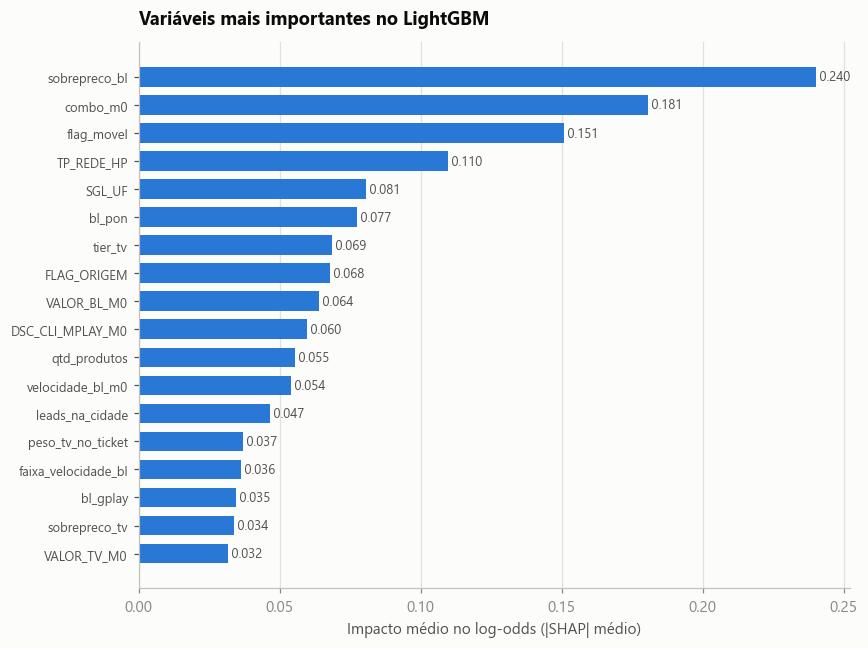

In [21]:
import shap

amostra = X[teste].sample(8000, random_state=SEED)
explicador = shap.TreeExplainer(gbm)
valores_shap = explicador.shap_values(amostra)
if isinstance(valores_shap, list):
    valores_shap = valores_shap[1]

importancia = (pd.Series(np.abs(valores_shap).mean(axis=0), index=amostra.columns)
                 .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(8, 6))
top = importancia.head(18)
vz.barras_h(ax, top.index, top.values, cor=vz.AZUL, fmt="{:.3f}")
ax.set_xlabel("Impacto médio no log-odds (|SHAP| médio)")
ax.set_title("Variáveis mais importantes no LightGBM")
ax.tick_params(axis="y", labelsize=8.5, colors=vz.TINTA_2)
plt.tight_layout(); salvar(fig, "11_importancia_shap"); plt.show()

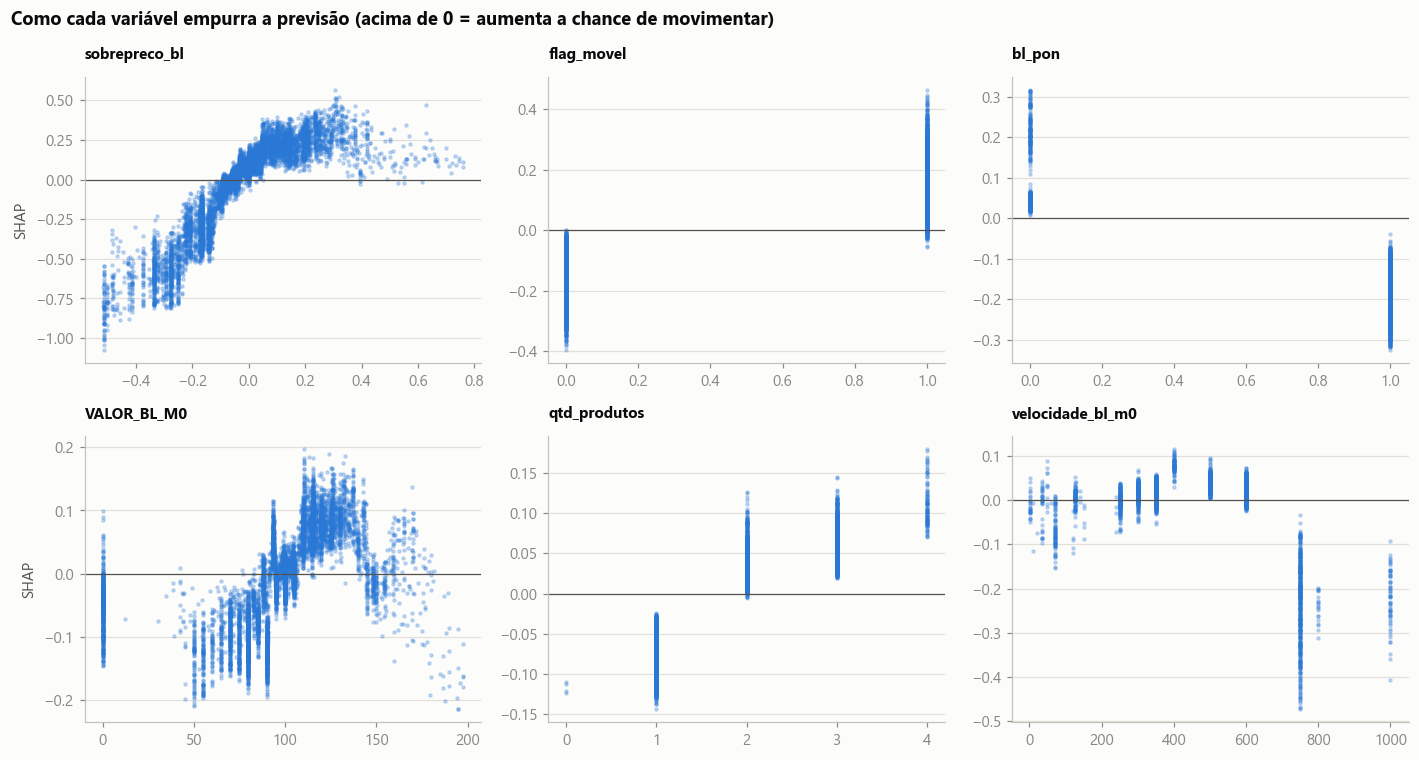

In [22]:
numericas_top = [v for v in importancia.index if v in VARS_NUMERICAS][:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, var in zip(axes.flat, numericas_top):
    i = list(amostra.columns).index(var)
    xv = amostra[var].astype(float)
    ok = xv.notna()
    if xv[ok].nunique() > 30:
        lim = xv[ok].quantile([.01, .99])
        ok &= xv.between(*lim)
    ax.scatter(xv[ok], valores_shap[ok.values, i], s=4, alpha=0.25, color=vz.AZUL, rasterized=True)
    ax.axhline(0, color=vz.TINTA_2, lw=0.8)
    ax.set_title(var, fontsize=10)
    ax.set_ylabel("SHAP" if ax in axes[:, 0] else "")
fig.suptitle("Como cada variável empurra a previsão (acima de 0 = aumenta a chance de movimentar)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(); salvar(fig, "12_dependencia_shap"); plt.show()

Sobrepreço é o fator mais importante; quem já está em 750M+ quase não troca (topo do catálogo).

## 7. Perfis
Árvore rasa (profundidade 4, folhas ≥ 4 mil leads); treino jun–out, taxa conferida em nov–dez.

In [23]:
from sklearn.tree import DecisionTreeClassifier

retidos["tem_sobrepreco_bl"] = retidos["sobrepreco_bl"].fillna(-1)
retidos["origem_solar"] = (retidos["FLAG_ORIGEM"] == "SOLAR").astype(int)
retidos["rede_gpon"] = (retidos["TP_REDE_HP"] == "GPON").astype(int)
vars_arvore = ["tem_tv", "tem_fone", "flag_movel", "qtd_produtos", "receita_m0", "VALOR_TV_M0",
               "tem_sobrepreco_bl", "velocidade_bl_m0", "plano_de_retencao_m0", "plano_old_m0",
               "origem_solar", "rede_gpon", "n_leads_anteriores"]
Xa = retidos[vars_arvore].fillna(0)

arvore = DecisionTreeClassifier(max_depth=4, min_samples_leaf=4000, random_state=SEED)
arvore.fit(Xa[treino], y[treino])
print(f"AUC da árvore no teste: {roc_auc_score(y[teste], arvore.predict_proba(Xa[teste])[:, 1]):.3f}")

regras = regras_folhas(arvore, vars_arvore)
retidos["folha"] = arvore.apply(Xa)

perfis = (retidos.groupby("folha")
            .agg(leads=("id_lead", "size"),
                 taxa_treino=("alvo_retido_mov", lambda s: s[treino[s.index]].mean()),
                 taxa_teste=("alvo_retido_mov", lambda s: s[teste[s.index]].mean()),
                 ticket_medio=("receita_m0", "mean"),
                 delta_receita_movimentadores=("delta_receita", lambda s: s[retidos.loc[s.index, "alvo_retido_mov"] == 1].mean()),
                 pct_troca_com_reducao=("tipo_desfecho", lambda s: (s == "Troca com reducao de valor").mean()))
            .sort_values("taxa_treino", ascending=False))
perfis["% dos retidos"] = perfis["leads"] / perfis["leads"].sum()
perfis["lift"] = perfis["taxa_treino"] / y[treino].mean()
perfis["regra"] = [texto_regra(regras[f]) for f in perfis.index]
perfis.insert(0, "perfil", [f"P{i + 1:02d}" for i in range(len(perfis))])
perfis

AUC da árvore no teste: 0.623


,perfil,leads,taxa_treino,taxa_teste,ticket_medio,delta_receita_movimentadores,pct_troca_com_reducao,% dos retidos,lift,regra
folha,,,,,,,,,,
26,P01,29067,0.523,0.531,267.424,-56.243,0.327,0.117,1.479,BL acima de -12% do preço típico · com móvel na operadora · 3+ produtos
19,P02,5548,0.478,0.448,191.000,-42.025,0.313,0.022,1.350,BL acima de +5% do preço típico · sem móvel na operadora · com rede GPON
25,P03,30211,0.448,0.458,196.590,-41.655,0.286,0.121,1.267,BL acima de -12% do preço típico · com móvel na operadora · 2 produtos
23,P04,12494,0.403,0.320,122.841,-35.363,0.320,0.050,1.140,BL acima de +5% do preço típico · com móvel na operadora · só 1 produto
10,P05,6501,0.375,0.363,71.488,11.960,0.075,0.026,1.058,BL até -12% do preço típico (ou sem BL) · 2+ produtos · com SOLAR · valor TV ≤ R$ 27
18,P06,5491,0.374,0.349,182.404,-31.162,0.217,0.022,1.058,BL entre -12% e +5% do preço típico · sem móvel na operadora · com rede GPON
16,P07,55520,0.334,0.297,232.283,-49.787,0.208,0.223,0.943,BL acima de -12% do preço típico · sem móvel na operadora · sem rede GPON · ticket > R$ 115
22,P08,17413,0.331,0.332,102.261,-26.489,0.282,0.070,0.937,BL entre -12% e +5% do preço típico · com móvel na operadora · só 1 produto
11,P09,27398,0.321,0.306,208.261,-31.462,0.160,0.110,0.906,BL até -12% do preço típico (ou sem BL) · 2+ produtos · com SOLAR · valor TV > R$ 27


| Grupo | Segmentos | % retidos | Taxa | Abordagem |
|---|---|---|---|---|
| Convergente no preço ou acima | P01, P03, P04, P08 | 36% | 33–53% | público principal da troca; priorizar troca com upgrade (P01 perde R$ 56 ao movimentar) |
| Sem móvel, BL cara | P02, P06, P07, P10 | 34% | 29–48% | migração de catálogo + oferta de móvel |
| Portfólio grande, preço bom | P05, P09, P11 | 18% | 28–37% | troca da TV linear por streaming |
| Single-play barato | P12, P13, P14 | 13% | 13–24% | reter sem mexer no plano |

Árvore tem AUC 0,62: serve de mapa; o LightGBM pontua.

## 8. SOLAR x Legado

Perfis diferentes, então comparo clientes equivalentes com ponderação por escore de propensão (IPW). É observacional – confirmar com A/B.

AUC do escore de propensão: 0.749


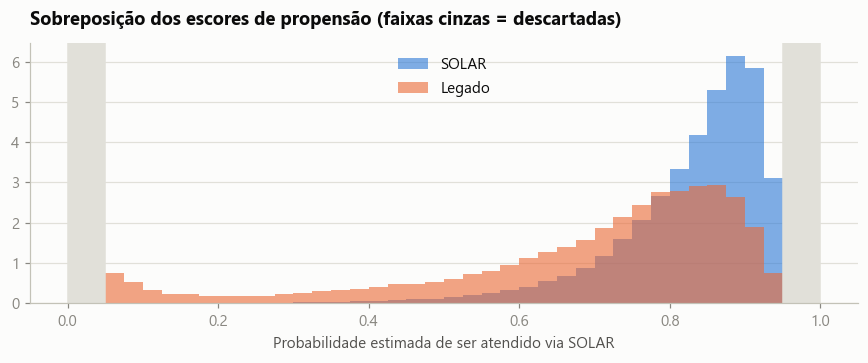

In [24]:
from sklearn.model_selection import cross_val_predict

fech = df[df["status"] != "LEAD EM ABERTO"].copy()
covars_cat = [c for c in VARS_CATEGORICAS if c != "FLAG_ORIGEM"] + ["mes"]
Xp = fech[VARS_NUMERICAS + covars_cat].copy()
for c in covars_cat:
    Xp[c] = Xp[c].astype("category")
tratado = (fech["FLAG_ORIGEM"] == "SOLAR").astype(int)

modelo_ps = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=300,
                               random_state=SEED, verbose=-1)
# previsão fora da amostra (5 folds) para não superajustar o escore
fech["ps"] = cross_val_predict(modelo_ps, Xp, tratado, cv=5, method="predict_proba")[:, 1]
print(f"AUC do escore de propensão: {roc_auc_score(tratado, fech['ps']):.3f}")

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 1, 41)
ax.hist(fech.loc[tratado == 1, "ps"], bins=bins, density=True, alpha=0.6, color=vz.AZUL, label="SOLAR")
ax.hist(fech.loc[tratado == 0, "ps"], bins=bins, density=True, alpha=0.6, color=vz.LARANJA, label="Legado")
ax.axvspan(0, 0.05, color=vz.GRADE); ax.axvspan(0.95, 1, color=vz.GRADE)
ax.legend(); ax.set_xlabel("Probabilidade estimada de ser atendido via SOLAR")
ax.set_title("Sobreposição dos escores de propensão (faixas cinzas = descartadas)")
plt.tight_layout(); salvar(fig, "14_propensao"); plt.show()

Descarto escores < 5% ou > 95%.

Leads mantidos no suporte comum: 290.586 de 297.400 (97.7%)


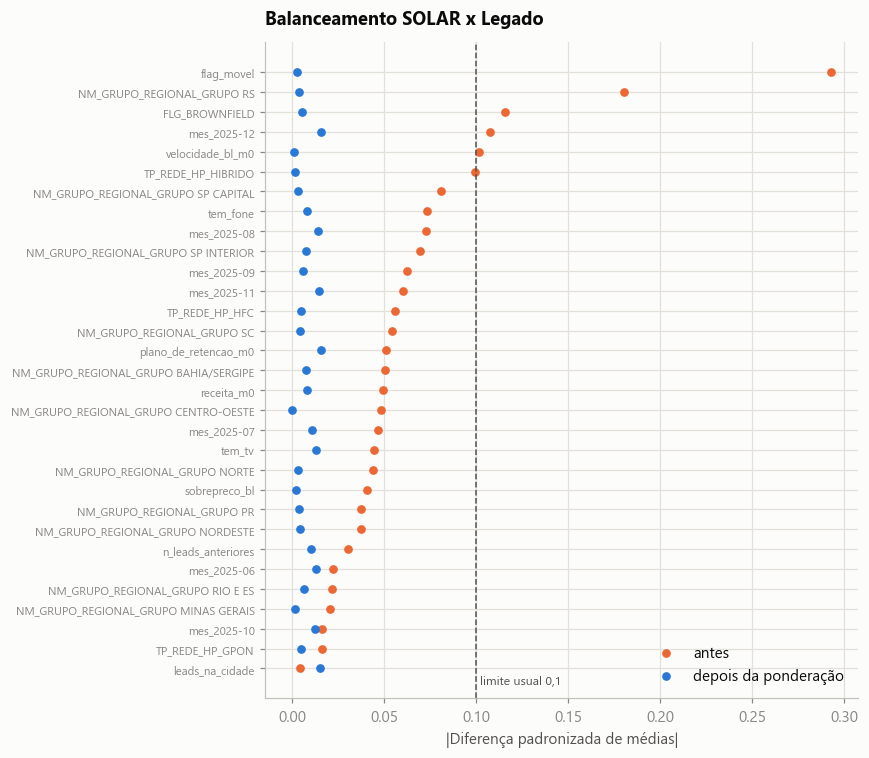

Variáveis acima de 0,1 – antes: 5 | depois: 0


In [25]:
suporte = fech["ps"].between(0.05, 0.95)
fc = fech[suporte].copy()
t = (fc["FLAG_ORIGEM"] == "SOLAR").astype(int).values
ps = fc["ps"].values
print(f"Leads mantidos no suporte comum: {br(suporte.sum())} de {br(len(fech))} ({suporte.mean():.1%})")

# Pesos: ATT = efeito para quem foi SOLAR | ATC = efeito se os leads de Legado fossem para SOLAR
peso_att = np.where(t == 1, 1, ps / (1 - ps))
peso_atc = np.where(t == 1, (1 - ps) / ps, 1)

def dif_padronizada(x, t, w):
    m1, m0 = np.average(x[t == 1], weights=w[t == 1]), np.average(x[t == 0], weights=w[t == 0])
    v1, v0 = np.var(x[t == 1]), np.var(x[t == 0])
    return (m1 - m0) / np.sqrt((v1 + v0) / 2 + 1e-12)

check = ["receita_m0", "tem_tv", "tem_fone", "flag_movel", "sobrepreco_bl", "velocidade_bl_m0",
         "plano_de_retencao_m0", "n_leads_anteriores", "leads_na_cidade", "FLG_BROWNFIELD"]
extras = pd.get_dummies(fc[["TP_REDE_HP", "NM_GRUPO_REGIONAL", "mes"]]).astype(float)
mat = pd.concat([fc[check].fillna(fc[check].median()), extras], axis=1)
balanco = pd.DataFrame({
    "antes": [dif_padronizada(mat[c].values, t, np.ones(len(t))) for c in mat],
    "depois (ATT)": [dif_padronizada(mat[c].values, t, peso_att) for c in mat],
}, index=mat.columns).abs()

fig, ax = plt.subplots(figsize=(8, 7))
b = balanco.sort_values("antes")
ax.scatter(b["antes"], b.index, color=vz.LARANJA, s=22, label="antes")
ax.scatter(b["depois (ATT)"], b.index, color=vz.AZUL, s=22, label="depois da ponderação")
ax.axvline(0.1, color=vz.TINTA_2, ls="--", lw=1)
ax.text(0.102, -0.8, "limite usual 0,1", fontsize=8, color=vz.TINTA_2)
ax.tick_params(axis="y", labelsize=7.5)
ax.grid(axis="x", visible=True)
ax.legend(loc="lower right"); ax.set_xlabel("|Diferença padronizada de médias|")
ax.set_title("Balanceamento SOLAR x Legado")
plt.tight_layout(); salvar(fig, "15_balanceamento"); plt.show()
print(f"Variáveis acima de 0,1 – antes: {(balanco['antes'] > .1).sum()} | depois: {(balanco['depois (ATT)'] > .1).sum()}")

Todas as variáveis abaixo de 0,1 após a ponderação. IC por bootstrap.

In [26]:
def efeito(y, t, w):
    return y[t == 1].dot(w[t == 1]) / w[t == 1].sum() - y[t == 0].dot(w[t == 0]) / w[t == 0].sum()

desfechos = {"retido": "Taxa de retenção", "alvo_retido_mov": "Retido com movimentação",
             "receita_m30": "Receita M30 por lead (R$)", "delta_receita": "Variação de receita por lead (R$)"}
rng = np.random.default_rng(SEED)
idx_boot = [rng.integers(0, len(fc), len(fc)) for _ in range(200)]

linhas = []
for col, nome in desfechos.items():
    yv = fc[col].values.astype(float)
    bruto = yv[t == 1].mean() - yv[t == 0].mean()
    att = efeito(yv, t, peso_att)
    atc = efeito(yv, t, peso_atc)
    boot = [efeito(yv[i], t[i], peso_att[i]) for i in idx_boot]
    boot_c = [efeito(yv[i], t[i], peso_atc[i]) for i in idx_boot]
    linhas.append({"desfecho": nome, "diferença bruta": bruto, "efeito ajustado (ATT)": att,
                   "IC 95% inf": np.percentile(boot, 2.5), "IC 95% sup": np.percentile(boot, 97.5),
                   "efeito se Legado fosse SOLAR (ATC)": atc,
                   "ATC IC inf": np.percentile(boot_c, 2.5), "ATC IC sup": np.percentile(boot_c, 97.5)})
efeitos = pd.DataFrame(linhas).set_index("desfecho")
efeitos

,diferença bruta,efeito ajustado (ATT),IC 95% inf,IC 95% sup,efeito se Legado fosse SOLAR (ATC),ATC IC inf,ATC IC sup
desfecho,,,,,,,
Taxa de retenção,0.025,0.082,0.077,0.086,0.052,0.049,0.055
Retido com movimentação,0.035,0.045,0.040,0.049,0.041,0.037,0.046
Receita M30 por lead (R$),-2.546,0.958,-0.324,2.530,-1.128,-2.159,0.027
Variação de receita por lead (R$),-7.428,1.762,0.704,2.752,-2.810,-3.601,-2.008


Bruto +2,5 p.p.; ajustado **+8,2 p.p.** O SOLAR atende uma carteira mais difícil.

Efeito se o Legado passasse a usar SOLAR (ATC):

In [27]:
meses = df["mes"].nunique()
leads_legado_mes = (fc["FLAG_ORIGEM"] == "LEGADO").sum() / meses
atc = efeitos[["efeito se Legado fosse SOLAR (ATC)", "ATC IC inf", "ATC IC sup"]]
ef_ret = atc.loc["Taxa de retenção"]
ef_rec = atc.loc["Receita M30 por lead (R$)"]

projecao = pd.DataFrame({
    "estimativa": [leads_legado_mes, ef_ret.iloc[0] * 100, leads_legado_mes * ef_ret.iloc[0],
                   leads_legado_mes * ef_rec.iloc[0], leads_legado_mes * ef_rec.iloc[0] * 12],
    "IC 95% inf": [np.nan, ef_ret.iloc[1] * 100, leads_legado_mes * ef_ret.iloc[1],
                   leads_legado_mes * ef_rec.iloc[1], leads_legado_mes * ef_rec.iloc[1] * 12],
    "IC 95% sup": [np.nan, ef_ret.iloc[2] * 100, leads_legado_mes * ef_ret.iloc[2],
                   leads_legado_mes * ef_rec.iloc[2], leads_legado_mes * ef_rec.iloc[2] * 12],
}, index=["Leads de Legado por mês (amostra)", "Ganho de retenção (p.p.)", "Clientes a mais retidos por mês",
          "Variação de receita mensal (R$)", "Variação de receita anualizada (R$)"])
projecao.style.format("{:,.1f}", na_rep="")

,estimativa,IC 95% inf,IC 95% sup
Leads de Legado por mês (amostra),"8,365.3",,
Ganho de retenção (p.p.),5.2,4.9,5.5
Clientes a mais retidos por mês,433.0,406.6,464.0
Variação de receita mensal (R$),"-9,434.3","-18,056.8",227.4
Variação de receita anualizada (R$),"-113,212.1","-216,681.5","2,728.4"


+5,2 p.p. (~430 clientes/mês na amostra), mas receita por lead levemente menor: expandir com piso de preço.

## 9. Modelo de triagem (usado no simulador)
Multiclasse com todos os leads finalizados: não retido / retido sem troca / retido com troca.

In [28]:
fech["classe"] = np.select([fech["retido"] == 0, fech["alvo_retido_mov"] == 0], [0, 1], 2)
nomes_classes = ["Não retido", "Retido sem mov.", "Retido com mov."]
Xf = fech[VARS].copy()
for c in VARS_CATEGORICAS:
    Xf[c] = Xf[c].astype("category")
tr_f, te_f = fech["mes"] <= "2025-10", fech["mes"] > "2025-10"

triagem = lgb.LGBMClassifier(objective="multiclass", n_estimators=600, learning_rate=0.03, num_leaves=48,
                             min_child_samples=200, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
                             reg_lambda=5, random_state=SEED, verbose=-1)
triagem.fit(Xf[tr_f], fech.loc[tr_f, "classe"])
p_tri = triagem.predict_proba(Xf[te_f])

res_tri = pd.DataFrame({
    "taxa no teste": [(fech.loc[te_f, "classe"] == k).mean() for k in range(3)],
    "AUC (um contra todos)": [roc_auc_score(fech.loc[te_f, "classe"] == k, p_tri[:, k]) for k in range(3)],
}, index=nomes_classes)
res_tri

,taxa no teste,AUC (um contra todos)
Não retido,0.174,0.848
Retido sem mov.,0.554,0.705
Retido com mov.,0.272,0.705


In [29]:
aux = pd.DataFrame(p_tri, columns=nomes_classes, index=fech.index[te_f])
aux["real"] = fech.loc[te_f, "classe"].map(dict(enumerate(nomes_classes)))
aux["receita_m0"] = fech.loc[te_f, "receita_m0"]
aux["delta_receita"] = fech.loc[te_f, "delta_receita"]
aux["faixa_risco"] = pd.qcut(aux["Não retido"], 5, labels=["muito baixo", "baixo", "médio", "alto", "muito alto"])

risco = aux.groupby("faixa_risco", observed=True).agg(
    leads=("real", "size"),
    taxa_nao_retido=("real", lambda s: (s == "Não retido").mean()),
    taxa_retido_mov=("real", lambda s: (s == "Retido com mov.").mean()),
    receita_m0_media=("receita_m0", "mean"),
    perda_media=("delta_receita", "mean"))
risco

,leads,taxa_nao_retido,taxa_retido_mov,receita_m0_media,perda_media
faixa_risco,,,,,
muito baixo,16814,0.010,0.359,220.749,-18.755
baixo,16813,0.036,0.340,173.695,-28.765
médio,16813,0.089,0.271,167.125,-37.655
alto,16813,0.221,0.235,166.441,-48.717
muito alto,16814,0.513,0.156,122.237,-60.530


Quintil de maior risco perde 51%; o de menor, 1%.

## 10. Conclusões

**Perfil:** paga acima do preço típico, é convergente, está em fibra e foi atendido pelo SOLAR. A troca costuma ser migração para o catálogo atual.

**Recomendações**
1. Sobrepreço como gatilho da oferta de troca.
2. Priorizar troca com upgrade antes de troca com desconto.
3. Medir retenção pela base de produtos em M30, não só pelo status.
4. Levar o SOLAR ao Legado via A/B, com piso de preço.

**Limitações:** sem a oferta apresentada, tempo de casa e motivo do cancelamento; efeito do SOLAR é observacional.

## 11. Exportação para o dashboard

In [30]:
import joblib, json

joblib.dump(gbm, DIR_MOD / "lgbm_retido_mov.pkl")
joblib.dump(triagem, DIR_MOD / "lgbm_triagem.pkl")

categorias = {c: list(X[c].cat.categories) for c in VARS_CATEGORICAS}
cidades = (df.groupby(["COD_IBGE", "DSC_CIDADE", "SGL_UF"])
             .agg(regional=("NM_GRUPO_REGIONAL", lambda s: s.mode()[0]),
                  classificacao=("CLASSIFICACAO", lambda s: s.mode()[0]),
                  rede=("TP_REDE_HP", lambda s: s.mode()[0]),
                  leads_na_cidade=("leads_na_cidade", "first"))
             .reset_index())
cidades = cidades[cidades["leads_na_cidade"] >= 30]   # evita expor cidades muito pequenas
ref_bl = (df[df["VALOR_BL_M0"] > 0].groupby(["faixa_velocidade_bl", "CLASSIFICACAO"])["VALOR_BL_M0"]
            .median().rename("ref").reset_index())
ref_tv = df[df["VALOR_TV_M0"] > 0].groupby("tier_tv")["VALOR_TV_M0"].median().rename("ref").reset_index()

agg_dims = ["mes", "FLAG_ORIGEM", "NM_GRUPO_REGIONAL", "SGL_UF", "combo_m0", "tier_tv",
            "faixa_velocidade_bl", "TP_REDE_HP", "CLASSIFICACAO", "status", "tipo_desfecho", "receita_zerada_m30"]
cubo = (df.groupby(agg_dims, observed=True)
          .agg(leads=("id_lead", "size"), retidos=("retido", "sum"), retido_mov=("alvo_retido_mov", "sum"),
               receita_m0=("receita_m0", "sum"), receita_m30=("receita_m30", "sum"))
          .reset_index())

cidades.to_parquet(DIR_APP / "cidades.parquet", index=False)
ref_bl.to_parquet(DIR_APP / "ref_bl.parquet", index=False)
ref_tv.to_parquet(DIR_APP / "ref_tv.parquet", index=False)
cubo.to_parquet(DIR_APP / "cubo.parquet", index=False)
perfis.to_parquet(DIR_APP / "perfis.parquet")
tipo.to_parquet(DIR_APP / "tipologia.parquet")
efeitos.to_parquet(DIR_APP / "efeito_solar.parquet")
balanco.to_parquet(DIR_APP / "balanceamento.parquet")
comparacao.to_parquet(DIR_APP / "comparacao_modelos.parquet")
dec_gbm.reset_index().assign(decil=lambda d: d["decil"].astype(int)).to_parquet(DIR_APP / "decis.parquet", index=False)
importancia.rename("shap").to_frame().to_parquet(DIR_APP / "importancia_shap.parquet")
matriz.to_parquet(DIR_APP / "matriz_velocidade.parquet")
matriz_tv.to_parquet(DIR_APP / "matriz_tv.parquet")
curva.reset_index(drop=True).to_parquet(DIR_APP / "curva_sobrepreco.parquet", index=False)
ponte.to_parquet(DIR_APP / "ponte_receita.parquet")
risco.to_parquet(DIR_APP / "faixas_risco.parquet")
projecao.to_parquet(DIR_APP / "projecao_solar.parquet")

meta = {"categorias": categorias, "vars_numericas": VARS_NUMERICAS, "vars_categoricas": VARS_CATEGORICAS,
        "taxa_mov_treino": float(y[treino].mean()), "classes_triagem": nomes_classes,
        "entrada_receita": float(entrada), "saida_receita": float(saida), "meses": int(meses),
        "limiar_risco_alto": float(aux["Não retido"].quantile(0.8))}
(DIR_APP / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")
print("Arquivos exportados:", sorted(p.name for p in DIR_APP.iterdir()))

Arquivos exportados: ['balanceamento.parquet', 'cidades.parquet', 'comparacao_modelos.parquet', 'cubo.parquet', 'curva_sobrepreco.parquet', 'decis.parquet', 'efeito_solar.parquet', 'faixas_risco.parquet', 'importancia_shap.parquet', 'matriz_tv.parquet', 'matriz_velocidade.parquet', 'meta.json', 'perfis.parquet', 'ponte_receita.parquet', 'projecao_solar.parquet', 'ref_bl.parquet', 'ref_tv.parquet', 'tipologia.parquet']
